# VLAD and Risk-Adjusted CUSUM (surgical outcomes)

**Family:** Healthcare & life sciences &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Healthcare & life sciences:* Clinical trials, survival, oncology, hospital quality and operations, epidemiology and patient-level records.

> ⚠️ Examples use simulated data. De-identify patient data before analysing it in notebooks: executed notebooks store their outputs.

## Design purpose

Two complementary charts for monitoring outcomes patient by patient while adjusting for how sick each patient was. The variable life-adjusted display (VLAD) plots cumulative expected minus observed deaths, an intuitive "statistical lives saved" line. The risk-adjusted Bernoulli CUSUM accumulates evidence that the odds of death have risen (here, doubled) and signals when that evidence crosses a threshold.

## When to use

- Monitor a surgeon, team or unit continuously, operation by operation, rather than in quarterly batches
- Adjust for case mix so that taking on high-risk patients isn't penalised
- Detect a sustained deterioration early, with a defined false-alarm behaviour

## Avoid when

- No validated pre-operative risk model exists (the charts are only as good as the expected risks)
- Events are very rare and volumes tiny (signals take years to accumulate)
- You only need a periodic comparison across units (use a funnel plot)

## Alternatives

- Funnel plot of risk-adjusted mortality across units
- p-chart of monthly mortality (simpler, but slower and not risk-adjusted per patient)
- Unadjusted CUSUM (penalises high-risk case mix)

## Design tips

- VLAD is for communication (easy to read); the risk-adjusted CUSUM is for decisions (it has a threshold)
- Each patient adds log(R/(1−p+Rp)) to the CUSUM if they die and log(1/(1−p+Rp)) if they survive, where p is their predicted risk and R the odds ratio to detect
- Choose the threshold h by simulation to balance false alarms against detection delay; h ≈ 4.5 is a common starting point
- Reset the CUSUM to zero after a signal and review the cases before continuing

## Example

600 simulated consecutive cardiac operations. Each patient's predicted risk of death comes from a pre-operative logistic model (average about 6%). From operation 400 onward the true odds of death are 2.5 times what the model predicts.

### Setup

In [1]:
import sys
from pathlib import Path
# This example uses the reusable vizlib package from this repository
# (or `pip install -e .` at the repo root).
sys.path.insert(0, str(Path(".").resolve().parents[1]))
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from vizlib.health import vlad, ra_cusum

### Data

In [2]:
rng = np.random.default_rng(1998)
n, change = 600, 400
logit = -3.1 + 0.8 * rng.normal(size=n) + 0.6 * rng.normal(size=n)   # pre-operative risk model
risk = 1 / (1 + np.exp(-logit))
odds = risk / (1 - risk)
true_odds = np.where(np.arange(n) >= change, odds * 2.5, odds)       # deterioration from op 400
died = (rng.random(n) < true_odds / (1 + true_odds)).astype(int)
h = 4.5
df = pd.DataFrame({"operation": np.arange(1, n + 1), "predicted_risk": risk.round(3), "died": died})
df["vlad"] = vlad(df["died"], df["predicted_risk"])
df["cusum"] = ra_cusum(df["died"], df["predicted_risk"], odds_ratio=2.0, h=h)
signals = df.index[df["cusum"] > h]
df.groupby(df["operation"] > change)[["died", "predicted_risk"]].sum().round(1)

,died,predicted_risk
operation,,
False,23,24.6
True,31,12.6


### Plot

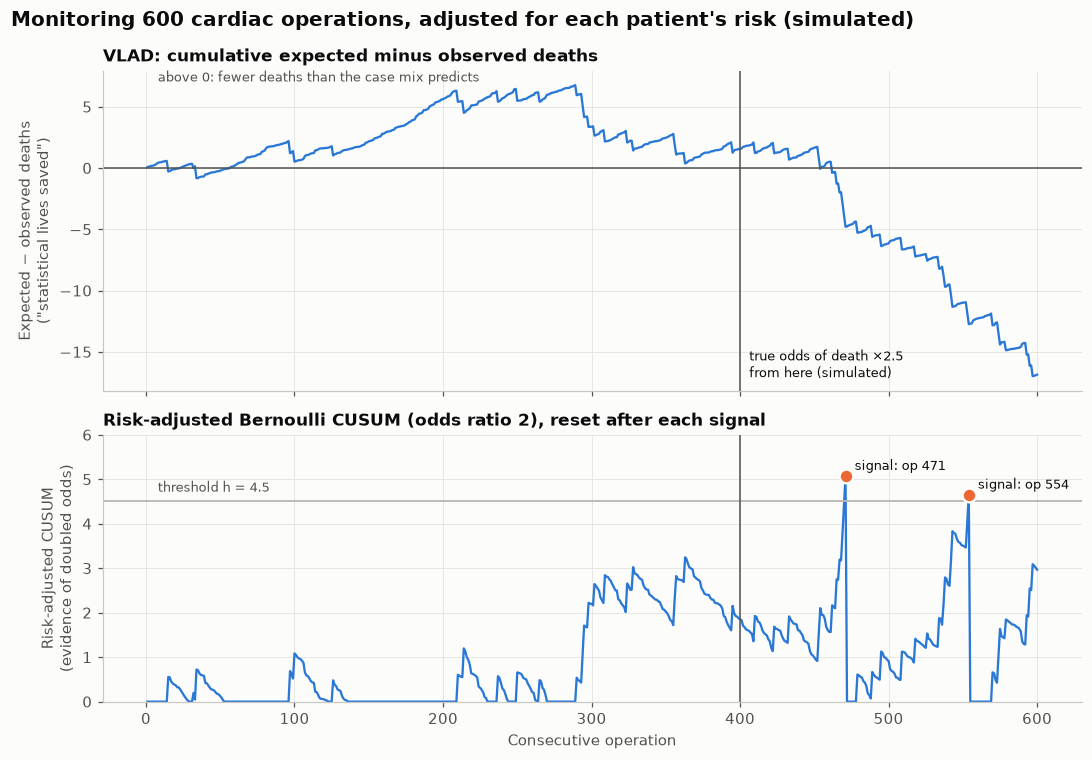

In [3]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})
x = df["operation"]
a1.plot(x, df["vlad"], color=PALETTE[0], linewidth=1.5)
a1.axhline(0, color="#52514e", linewidth=1)
a1.set_ylabel("Expected − observed deaths\n(\"statistical lives saved\")")
a1.set_title("VLAD: cumulative expected minus observed deaths", fontsize=11)
a1.text(8, a1.get_ylim()[1], "above 0: fewer deaths than the case mix predicts", fontsize=8.5,
        color="#52514e", va="top")
a2.plot(x, df["cusum"], color=PALETTE[0], linewidth=1.5)
a2.axhline(h, color="#b8b7b1", linewidth=1.2)
a2.text(8, h + 0.15, f"threshold h = {h}", fontsize=8.5, color="#52514e", va="bottom")
a2.scatter(x[signals], df["cusum"][signals], s=80, color=PALETTE[1], edgecolor="#fcfcfb", linewidth=1.5,
           zorder=4)
for i in signals:
    a2.annotate(f"signal: op {x[i]}", (x[i], df['cusum'][i]), xytext=(6, 4), textcoords="offset points",
                fontsize=8.5)
a2.set_ylim(0, h + 1.5)
a2.set_ylabel("Risk-adjusted CUSUM\n(evidence of doubled odds)")
a2.set_xlabel("Consecutive operation")
a2.set_title("Risk-adjusted Bernoulli CUSUM (odds ratio 2), reset after each signal", fontsize=11)
for ax in (a1, a2):
    ax.axvline(change, color="#52514e", linewidth=1)
a1.annotate("true odds of death ×2.5\nfrom here (simulated)", (change, a1.get_ylim()[0]), xytext=(6, 6),
            textcoords="offset points", fontsize=8.5, va="bottom")
fig.suptitle("Monitoring 600 cardiac operations, adjusted for each patient's risk (simulated)", x=0.01,
             ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
plt.show()

## How to read it

For the first 400 operations the VLAD stays within a few lives of zero (it drifts up to about +6 and back purely by chance): observed deaths track the case mix. After operation 400 it falls steadily, meaning more deaths than expected. The risk-adjusted CUSUM confirms this formally: it crosses the threshold at operations 471 and 554 (orange markers, reset after each) and never during the in-control period, even when the VLAD's chance dip around operation 300 looks alarming.

## Reference

This method comes from the research literature:

- Lovegrove, J., Valencia, O., Treasure, T., Sherlaw-Johnson, C. & Gallivan, S. (1997). Monitoring the results of cardiac surgery by variable life-adjusted display. The Lancet 350, 1128–1130. <https://doi.org/10.1016/S0140-6736%2897%2906507-0>
- Steiner, S. H., Cook, R. J. & Farewell, V. T. (2001). Risk-adjusted monitoring of binary surgical outcomes. Medical Decision Making 21(3), 163–169. <https://doi.org/10.1177/0272989X0102100301>

---
Standalone script: [`vlad_cusum.py`](vlad_cusum.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)